In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler , MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from scipy import sparse

from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


## Partie 1 : Explorer et vérifier les données

## Question 1

In [9]:
data=pd.read_csv(r'C:\Users\yassine\Desktop\TP\données de transactions bancaires\transactions_TP2.csv')

In [6]:
data.head(10)

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0
5,OP00615,C10321,1443.65,143.0,4.0,8,NaN,mobile,Souss-Massa,oui,aucune_fraude,0
6,OP01080,C10347,112.06,46.0,3.0,20,application,NaN,Marrakech-Safi,oui,aucune_fraude,0
7,OP01737,C10070,2260.29,20.0,3.0,16,site_web,ordinateur,Autre,non,aucune_fraude,0
8,OP02509,C10105,1103.46,18.0,1.0,7,site_web,ordinateur,Draa-Tafilalet,non,aucune_fraude,0
9,OP00560,C10346,624.20,128.0,NaN,22,NaN,ordinateur,Draa-Tafilalet,oui,aucune_fraude,0


In [7]:
data.shape

(3045, 12)

In [8]:
data.describe()

,montant_dh,anciennete_mois,nb_ops_24h,heure,fraude
count,2935.000000,2908.000000,2992.000000,3045.000000,3045.00000
mean,1034.646027,88.443948,2.700869,11.422660,0.08670
std,1358.953915,50.810303,1.644548,7.000024,0.28144
min,36.410000,0.000000,0.000000,0.000000,0.00000
25%,389.530000,44.000000,2.000000,5.000000,0.00000
50%,709.730000,89.000000,3.000000,11.000000,0.00000
75%,1249.585000,133.000000,4.000000,18.000000,0.00000
max,33281.230000,174.000000,11.000000,23.000000,1.00000


## Question 2

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3045 entries, 0 to 3044
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_operation      3045 non-null   str    
 1   id_client         3045 non-null   str    
 2   montant_dh        2935 non-null   float64
 3   anciennete_mois   2908 non-null   float64
 4   nb_ops_24h        2992 non-null   float64
 5   heure             3045 non-null   int64  
 6   canal             2886 non-null   str    
 7   appareil          2923 non-null   str    
 8   region            2942 non-null   str    
 9   international     3045 non-null   str    
 10  resultat_enquete  3045 non-null   str    
 11  fraude            3045 non-null   int64  
dtypes: float64(3), int64(2), str(7)
memory usage: 285.6 KB


In [11]:
data_missing= data.isnull().sum() #nombre des valeurs  manquant
print (data_missing)

id_operation          0
id_client             0
montant_dh          110
anciennete_mois     137
nb_ops_24h           53
heure                 0
canal               159
appareil            122
region              103
international         0
resultat_enquete      0
fraude                0
dtype: int64


In [12]:
data_null_percentage=data.isnull().mean()*100  #percentage of null values in columns
print(data_null_percentage)

id_operation        0.000000
id_client           0.000000
montant_dh          3.612479
anciennete_mois     4.499179
nb_ops_24h          1.740558
heure               0.000000
canal               5.221675
appareil            4.006568
region              3.382594
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64


In [13]:
missing_table = pd.DataFrame({   #Créer un tableau récapitulatif
    'Nombre manquant':data_missing,
    'Pourcentage (%)':data_null_percentage
})

In [14]:
missing_table = missing_table.sort_values(    ## Trier par pourcentage décroissant
    by = 'Pourcentage (%)',
    ascending=False
)
print (missing_table)

                  Nombre manquant  Pourcentage (%)
canal                         159         5.221675
anciennete_mois               137         4.499179
appareil                      122         4.006568
montant_dh                    110         3.612479
region                        103         3.382594
nb_ops_24h                     53         1.740558
id_operation                    0         0.000000
id_client                       0         0.000000
heure                           0         0.000000
international                   0         0.000000
resultat_enquete                0         0.000000
fraude                          0         0.000000


<Axes: >

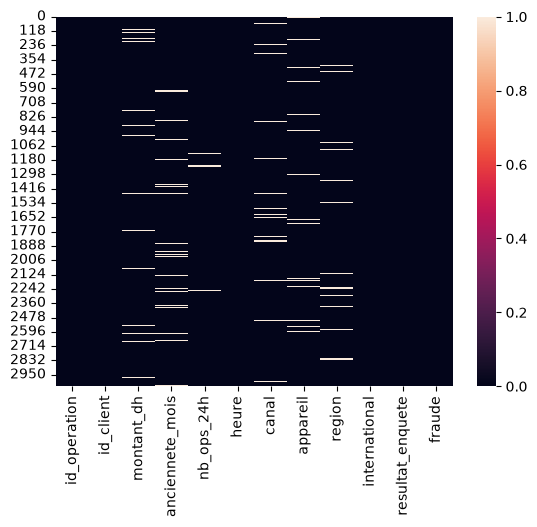

In [15]:
sns.heatmap(data.isnull())

## Question 3

In [19]:
nombre_doublons=data.duplicated(subset=['id_operation']).sum()
print(f"Nombre de doublons trouvés : {nombre_doublons}")

Nombre de doublons trouvés : 0


In [20]:
data = data.drop_duplicates(subset='id_operation')    # Supprimer ligns doublons en fct de id_operation
print(f"Nombre de doublons trouvés : {nombre_doublons}")

Nombre de doublons trouvés : 0


In [21]:
data.shape

(3000, 12)

## Question 4

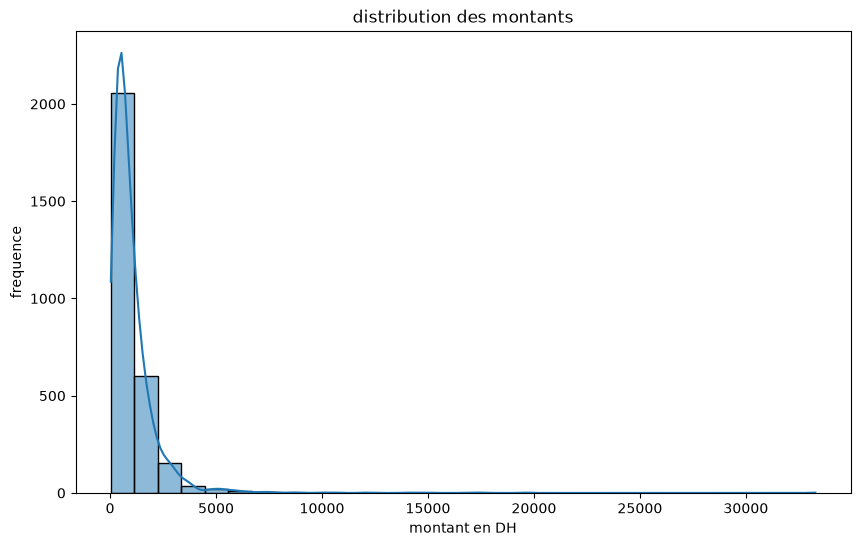

In [22]:
                                                   # histogramme
plt.figure(figsize=(10, 6))

sns.histplot(data['montant_dh'], bins=30, kde=True)

plt.title("distribution des montants")
plt.xlabel("montant en DH")
plt.ylabel("frequence")

plt.show()

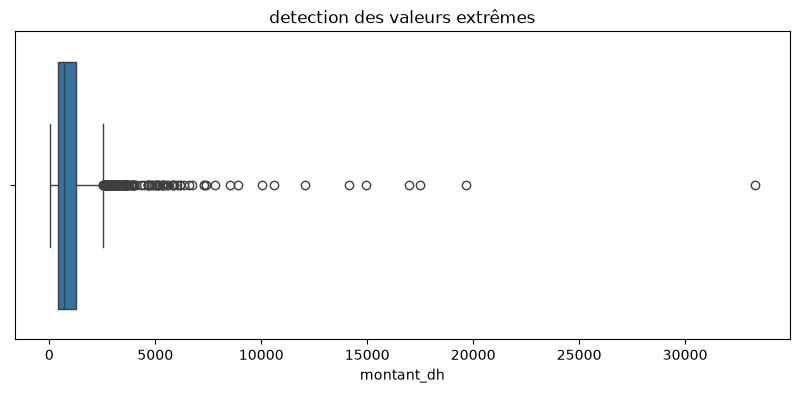

In [23]:
                                    # Boxplot
plt.figure(figsize=(10, 4))

sns.boxplot(x=data['montant_dh'])

plt.title("detection des valeurs extrêmes")

plt.show()

## reponce : Une valeur extrême n'est pas forcément une erreur,Il faut examiner les données avant de décider de les supprimer.



## Question 5

In [24]:
data['fraude'].value_counts() # Compter les classes

fraude
0    2742
1     258
Name: count, dtype: int64

In [25]:
data['fraude'].value_counts(normalize=True) * 100 #Calculer les proportions

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64

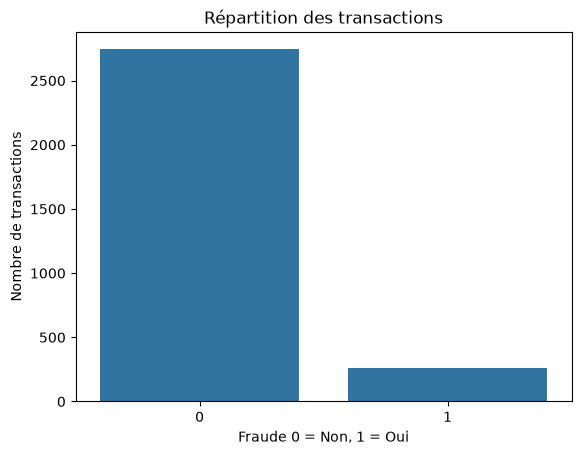

In [26]:
sns.countplot(data=data, x='fraude')
plt.title("Répartition des transactions")
plt.xlabel("Fraude 0 = Non, 1 = Oui")
plt.ylabel("Nombre de transactions")
plt.show()

## data est desequilibree car ona 2742 normale et 258 fraude (modèle pourrait privilégier la classe majoritaire et mal détecter les fraudes)



## Question 6

## Les colonnes id_operation et id_client sont des identifiants utilisés uniquement pour reconnaître les transactions et les clients. Elles ne représentent pas des caractéristiques pertinentes pour l'analyse des transactions et ne doivent donc pas être utilisées comme variables explicatives.

## La colonne resultat_enquete contient une information obtenue après la réalisation de la transaction, lorsque l'enquête bancaire est terminée. Elle doit être exclue car cette information n'est pas disponible au moment où une nouvelle transaction doit être analysée.

# Son utilisation provoquerait une fuite d'information (Data Leakage), car elle introduirait dans les données une information provenant du futur

In [27]:
# Afficher les identifiants et la colonne resultat_enquete
print(data[['id_operation', 'id_client', 'resultat_enquete']].head())

  id_operation id_client resultat_enquete
0      OP02438    C10278    aucune_fraude
1      OP00157    C10019    aucune_fraude
2      OP01987    C10604    aucune_fraude
3      OP00207    C10330    aucune_fraude
4      OP00738    C10380    aucune_fraude





# Partie 2 — Préparer les données sans fuite

In [28]:
                 ## separation var cible et explicative
X= data.drop(
    columns = ['id_operation', 'id_client','resultat_enquete', 'fraude']
)

Y= data['fraude']


print("Dimensions de X :", X.shape)
print("Dimensions de y :", Y.shape)
print("\nVariables explicatives :")
print(X.head())

print("\nVariable cible :")
print(Y.head())

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)

Variables explicatives :
   montant_dh  anciennete_mois  nb_ops_24h  heure        canal    appareil  \
0     5396.62             90.0         6.0     11     site_web      mobile   
1      438.41             55.0         2.0     22  application      mobile   
2     2846.79              NaN         1.0     10    telephone  ordinateur   
3      914.14            127.0         4.0      7  application      mobile   
4      228.23            110.0         4.0      5  application    terminal   

              region international  
0     Marrakech-Safi           non  
1        Souss-Massa           non  
2  Casablanca-Settat           non  
3  Casablanca-Settat           non  
4  Casablanca-Settat           non  

Variable cible :
0    0
1    0
2    0
3    0
4    0
Name: fraude, dtype: int64


In [29]:
X_ref, X_verif, Y_ref, Y_verif = train_test_split(X, Y, test_size=0.2,random_state=42,stratify=Y)

In [30]:
print("Référence :", X_ref.shape)
print("Vérification :", X_verif.shape)

print("\nProportion des fraudes - Référence :")
print(Y_ref.value_counts(normalize=True) * 100)

print("\nProportion des fraudes - Vérification :")
print(Y_verif.value_counts(normalize=True) * 100)

Référence : (2400, 8)
Vérification : (600, 8)

Proportion des fraudes - Référence :
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

Proportion des fraudes - Vérification :
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


In [31]:
# Variables numériques
num_cols = X_ref.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Variables catégorielles
cat_cols = X_ref.select_dtypes(
    include=['str', 'category', 'bool']
).columns.tolist()

print("Variables numériques :", num_cols)
print("Variables catégorielles :", cat_cols)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['canal', 'appareil', 'region', 'international']


In [32]:
          ## Pipeline numérique(z-scale)
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [33]:
        # Pipeline catégoriel

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [34]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

In [35]:
#  uniquement sur le groupe de référence
X_ref_preparer = preprocessor.fit_transform(X_ref)

# Appliquer les mêmes paramètres au groupe de vérification
X_verif_preparer = preprocessor.transform(X_verif)

In [36]:
print("Référence :", X_ref_preparer.shape)
print("Vérification :", X_verif_preparer.shape)

Référence : (2400, 18)
Vérification : (600, 18)


In [37]:
      #Pipeline numérique(RobustScaler)
robust_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

In [38]:
# StandardScaler
numeric_pipeline.fit(X_ref[['montant_dh']])

standard_values = numeric_pipeline.transform(
    X_ref[['montant_dh']]
)

# RobustScaler
robust_pipeline.fit(X_ref[['montant_dh']])

robust_values = robust_pipeline.transform(
    X_ref[['montant_dh']]
)

In [39]:
comparison = pd.DataFrame({
    'Montant_initial': X_ref['montant_dh'].values,
    'StandardScaler': standard_values.flatten(),
    'RobustScaler': robust_values.flatten()
})

print(comparison.head(10))

   Montant_initial  StandardScaler  RobustScaler
0           419.53       -0.452796     -0.356740
1           533.01       -0.367320     -0.217748
2           477.87       -0.408852     -0.285284
3          2518.08        1.127884      2.213595
4           394.74       -0.471468     -0.387103
5           658.53       -0.272775     -0.064009
6           250.89       -0.579819     -0.563292
7           421.09       -0.451621     -0.354829
8           402.85       -0.465359     -0.377169
9           479.71       -0.407467     -0.283030


In [75]:
print(
    comparison.sort_values(
        by='Montant_initial',
        ascending=False
    ).head(10)
)

      Montant_initial  StandardScaler  RobustScaler
88           33281.23       24.299442     39.892755
550          19658.42       14.038408     23.207337
1514         17496.64       12.410102     20.559557
532          14951.95       10.493379     17.442783
1317         14135.85        9.878673     16.443211
893          10598.93        7.214578     12.111140
980          10028.37        6.784818     11.412309
730           8910.60        5.942886     10.043248
480           7823.15        5.123792      8.711323
1638          7400.94        4.805774      8.194194


# Il ne faut jamais appliquer fit() sur les données de vérification, car cela entraîne une fuite de données (Data Leakage). En effet, les paramètres du prétraitement (moyenne, médiane, écart-type, etc.) doivent être calculés uniquement à partir des données de référence. Ensuite, ces mêmes paramètres sont appliqués aux données de vérification avec transform(). Cette méthode garantit une séparation correcte entre les deux groupes et permet d'obtenir une évaluation fiable.

In [40]:
# Apprendre les parametres et transformer les donnes de reference
X_ref_prepared = preprocessor.fit_transform(X_ref)

# Appliquer les memes parametres aux donnees de verification
X_verif_prepared = preprocessor.transform(X_verif)


## Partie 3 — Comparer les méthodes de mise à l’échelle

In [41]:
Q1 = X_ref['montant_dh'].quantile(0.25)
Q3 = X_ref['montant_dh'].quantile(0.75)


IQR = Q3 - Q1

# les limites
limite_min = Q1 - 1.5 * IQR
limite_max = Q3 + 1.5 * IQR

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)
print("Limite minimale :", limite_min)
print("Limite maximale :", limite_max)

Q1 : 393.095
Q3 : 1249.8775
IQR : 856.7825
Limite minimale : -892.0787499999999
Limite maximale : 2535.05125


In [42]:
outliers = X_ref[
    (X_ref['montant_dh'] < limite_min) |
    (X_ref['montant_dh'] > limite_max)
]

print("Nombre de valeurs extrêmes :", len(outliers))
print(outliers[['montant_dh']].head(10))

Nombre de valeurs extrêmes : 146
      montant_dh
1601     2940.62
1348     3449.17
2660    33281.23
1489     3988.17
2049     3942.99
2088     2645.74
1105     6733.98
1074     2535.89
396      3002.07
329      5021.72


In [43]:
# Cas 1 conserver les montants extremes
montants_originaux = X_ref['montant_dh']

# Cas 2 limiter les montants aux seuil IQR
montants_limites = X_ref['montant_dh'].clip(
    lower=limite_min,
    upper=limite_max
)

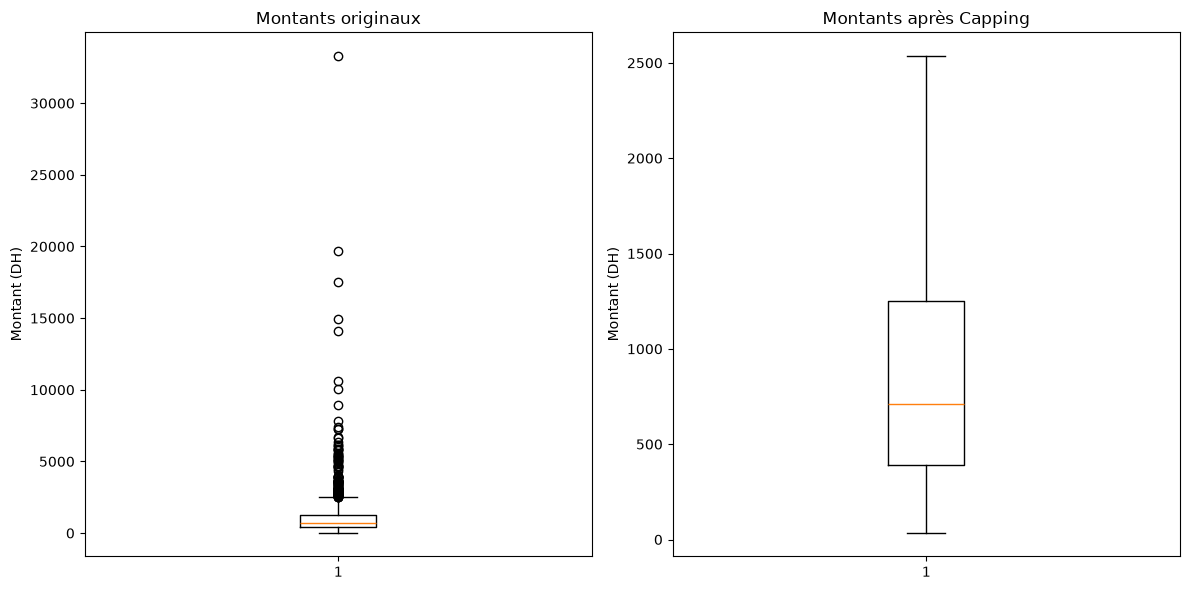

In [47]:
plt.figure(figsize=(12, 6))

# Premier boxplot :donnes originales
plt.subplot(1, 2, 1)
plt.boxplot(montants_originaux.dropna())
plt.title("Montants originaux")
plt.ylabel("Montant (DH)")

# Deuxieme boxplot : donnees apres Capping
plt.subplot(1, 2, 2)
plt.boxplot(montants_limites.dropna())
plt.title("Montants après Capping")
plt.ylabel("Montant (DH)")

plt.tight_layout()
plt.show()

In [49]:
# Pipeline MinMaxScaler
minmax_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

# Pipeline StandardScaler
standard_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline RobustScaler
robust_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

In [54]:
minmax_pipeline.fit(X_ref[['montant_dh']])
standard_pipeline.fit(X_ref[['montant_dh']])
robust_pipeline.fit(X_ref[['montant_dh']])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['montant_dh']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will b

In [58]:
# Transformer le groupe de reference
ref_minmax = minmax_pipeline.transform(X_ref[['montant_dh']])
ref_standard = standard_pipeline.transform(X_ref[['montant_dh']])
ref_robust = robust_pipeline.transform(X_ref[['montant_dh']])


# Transformer le groupe de verification
verif_minmax = minmax_pipeline.transform(X_verif[['montant_dh']])
verif_standard = standard_pipeline.transform(X_verif[['montant_dh']])
verif_robust = robust_pipeline.transform(X_verif[['montant_dh']])

In [59]:
comparison_ref = pd.DataFrame({
    'Montant_initial': X_ref['montant_dh'].values,
    'MinMaxScaler': ref_minmax.flatten(),
    'StandardScaler': ref_standard.flatten(),
    'RobustScaler': ref_robust.flatten()
})

print(comparison_ref.head(10))

   Montant_initial  MinMaxScaler  StandardScaler  RobustScaler
0           419.53      0.011524       -0.452796     -0.356740
1           533.01      0.014938       -0.367320     -0.217748
2           477.87      0.013279       -0.408852     -0.285284
3          2518.08      0.074648        1.127884      2.213595
4           394.74      0.010779       -0.471468     -0.387103
5           658.53      0.018713       -0.272775     -0.064009
6           250.89      0.006452       -0.579819     -0.563292
7           421.09      0.011571       -0.451621     -0.354829
8           402.85      0.011022       -0.465359     -0.377169
9           479.71      0.013334       -0.407467     -0.283030


In [65]:
comparison_verif = pd.DataFrame({
    'Montant_initial': X_verif['montant_dh'].values,
    'MinMaxScaler': verif_minmax.flatten(),
    'StandardScaler': verif_standard.flatten(),
    'RobustScaler': verif_robust.flatten()
})

print(comparison_verif.head(10))

   Montant_initial  MinMaxScaler  StandardScaler  RobustScaler
0           795.50      0.022833       -0.169606      0.103754
1          1144.86      0.033342        0.093541      0.531655
2           259.10      0.006698       -0.573635     -0.553237
3           347.80      0.009367       -0.506824     -0.444596
4           451.36      0.012482       -0.428820     -0.317754
5           574.89      0.016197       -0.335775     -0.166452
6          1801.63      0.053098        0.588236      1.336077
7           498.07      0.013887       -0.393637     -0.260543
8           764.14      0.021890       -0.193227      0.065344
9           485.04      0.013495       -0.403452     -0.276502


In [82]:
# Ignorer les valeurs manquantes
montants = X_ref['montant_dh'].dropna()

# Sélectionner trois montants habituels
montant_1 = montants.loc[(montants - montants.quantile(0.25)).abs().idxmin()]
montant_2 = montants.loc[(montants - montants.median()).abs().idxmin()]
montant_3 = montants.loc[(montants - montants.quantile(0.75)).abs().idxmin()]

# Slectionner le montant le plus eleve
montant_eleve = montants.max()

# Creer un tableau des montants choisis
montants_choisis = pd.DataFrame({
    'Montant_initial': [
        montant_1,
        montant_2,
        montant_3,
        montant_eleve
    ]
}, index=[
    'Montant habituel 1',
    'Montant habituel 2',
    'Montant habituel 3',
    'Montant très élevé'
])

montants_choisis

,Montant_initial
Montant habituel 1,393.10
Montant habituel 2,710.29
Montant habituel 3,1249.69
Montant très élevé,33281.23


In [79]:
# Renommer la colonne pour respecter le nom utilis dans fit
montants_a_transformer = montants_choisis[['Montant_initial']].rename(
    columns={'Montant_initial': 'montant_dh'}
)

# Appliquer les trois transformations
valeurs_minmax = minmax_pipeline.transform(montants_a_transformer)
valeurs_standard = standard_pipeline.transform(montants_a_transformer)
valeurs_robust = robust_pipeline.transform(montants_a_transformer)

# Construire le tableau comparatif
tableau_comparaison = pd.DataFrame({
    'Montant_initial': montants_choisis['Montant_initial'].values,
    'MinMaxScaler': valeurs_minmax.flatten(),
    'StandardScaler': valeurs_standard.flatten(),
    'RobustScaler': valeurs_robust.flatten()
}, index=montants_choisis.index)

tableau_comparaison.round(4)

,Montant_initial,MinMaxScaler,StandardScaler,RobustScaler
Montant habituel 1,393.10,0.0107,-0.4727,-0.3891
Montant habituel 2,710.29,0.0203,-0.2338,-0.0006
Montant habituel 3,1249.69,0.0365,0.1725,0.6601
Montant très élevé,33281.23,1.0000,24.2994,39.8928


## Nous avons comparé trois montants habituels et un montant très élevé (33 281,23 DH) après application des trois méthodes de normalisation. Les résultats montrent que MinMaxScaler est fortement influencé par la valeur maximale, ce qui rapproche les montants habituels de zéro. StandardScaler est également sensible aux valeurs extrêmes, car il utilise la moyenne et l'écart-type. En revanche, RobustScaler utilise la médiane et l'écart interquartile, ce qui le rend moins sensible aux valeurs extrêmes. Ainsi, RobustScaler représente un choix intéressant pour les données bancaires contenant des montants très élevés.

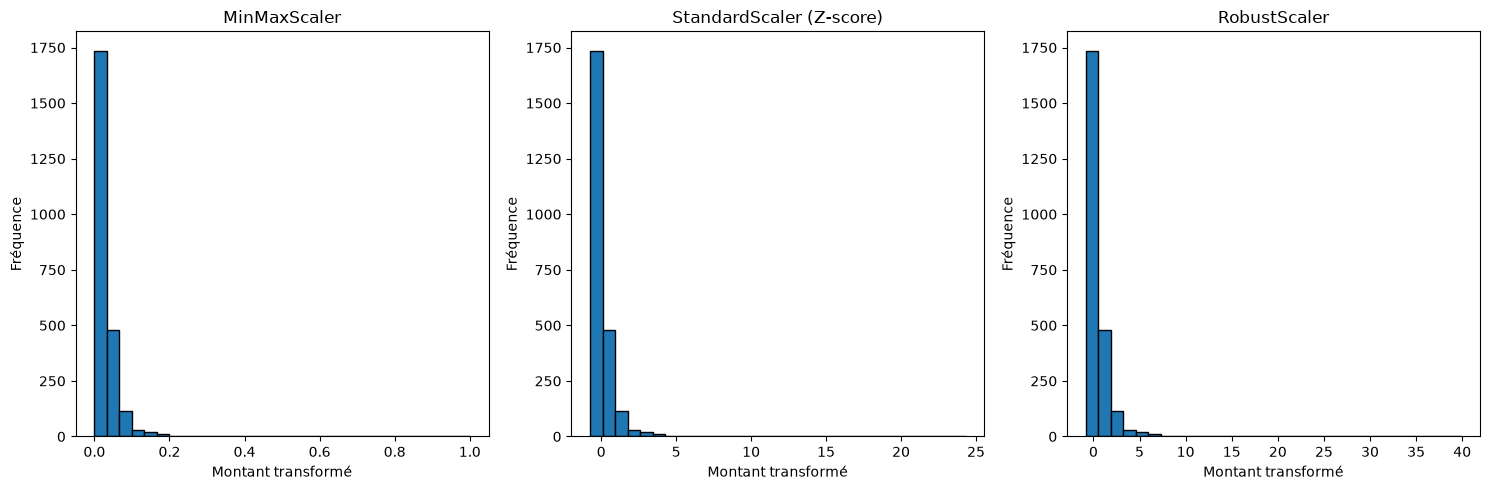

In [70]:
plt.figure(figsize=(15, 5))

# Histogramme MinMaxScaler
plt.subplot(1, 3, 1)
plt.hist(ref_minmax.flatten(), bins=30, edgecolor='black')
plt.title("MinMaxScaler")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")

# Histogramme StandardScaler
plt.subplot(1, 3, 2)
plt.hist(ref_standard.flatten(), bins=30, edgecolor='black')
plt.title("StandardScaler (Z-score)")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")

# Histogramme RobustScaler
plt.subplot(1, 3, 3)
plt.hist(ref_robust.flatten(), bins=30, edgecolor='black')
plt.title("RobustScaler")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")

plt.tight_layout()
plt.show()

## Oui, avec MinMaxScaler, une nouvelle valeur peut dépasser 1 si elle est supérieure au maximum observé dans le groupe de référence





## Partie 4 — Préparer des classes déséquilibrées

In [92]:
# Compter les transactions de chaque classe
Y_ref.value_counts().sort_index()



fraude
0    2194
1     206
Name: count, dtype: int64

In [93]:
nb_normal = distribution[0]
nb_fraude = distribution[1]
rapport = nb_normal / nb_fraude
print("Rapport normal / fraude :", round(rapport, 2))

Rapport normal / fraude : 10.65


In [90]:
pourcentage = Y_ref.value_counts(normalize=True).sort_index() * 100

print("\nPourcentage de chaque classe :")
pourcentage.round(2)




Pourcentage de chaque classe :


fraude
0    91.42
1     8.58
Name: proportion, dtype: float64

In [97]:
print("Avant rééquilibrage :")
Y_ref.value_counts().sort_index()

Avant rééquilibrage :


fraude
0    2194
1     206
Name: count, dtype: int64

In [98]:
          ## Appliquer RandomOverSampler

# Créer le rééchantillonneur
ros = RandomOverSampler(random_state=42)

# Appliquer le rééquilibrage
X_ref_over, Y_ref_over = ros.fit_resample(X_ref, Y_ref)

In [100]:
print("Après rééquilibrage :")
print(Y_ref_over.value_counts().sort_index())

Après rééquilibrage :
fraude
0    2194
1    2194
Name: count, dtype: int64


In [101]:
print("Nombre de lignes avant :", len(X_ref))
print("Nombre de lignes après :", len(X_ref_over))

Nombre de lignes avant : 2400
Nombre de lignes après : 4388


In [103]:
print("Avant rééquilibrage :")
print(Y_ref.value_counts().sort_index())

Avant rééquilibrage :
fraude
0    2194
1     206
Name: count, dtype: int64


In [104]:
      ## Appliquer RandomUnderSampler

# Créer le rééchantillonneur
rus = RandomUnderSampler(random_state=42)

# Appliquer le rééquilibrage
X_ref_under, Y_ref_under = rus.fit_resample(X_ref, Y_ref)

In [105]:
print("Après rééquilibrage :")
print(Y_ref_under.value_counts().sort_index())

print("\nNombre de lignes avant :", len(X_ref))
print("Nombre de lignes après :", len(X_ref_under))

Après rééquilibrage :
fraude
0    206
1    206
Name: count, dtype: int64

Nombre de lignes avant : 2400
Nombre de lignes après : 412


In [106]:
# Nombre de lignes supprim
lignes_supprimees = len(X_ref) - len(X_ref_under)

# Nombre de lignes conservées
lignes_conservees = len(X_ref_under)

print("Lignes conservées :", lignes_conservees)
print("Lignes supprimées :", lignes_supprimees)

Lignes conservées : 412
Lignes supprimées : 1988




## Le principal risque est la perte d'informations. RandomUnderSampler supprime aléatoirement des transactions de la classe majoritaire. Certaines observations utiles peuvent donc être perdues.



In [107]:

# Deux observations de la classe minoritaire
A = np.array([1000, 5])
B = np.array([2000, 9])

# Valeur aléatoire
lambda_ = 0.5

# Générer une observation synthétique
nouvelle = A + lambda_ * (B - A)

print("Observation A :", A)
print("Observation B :", B)
print("Observation synthétique :", nouvelle)

Observation A : [1000    5]
Observation B : [2000    9]
Observation synthétique : [1500.    7.]


## SMOTE : données numériques.



## SMOTENC : données numériques + catégorielles.



## SMOTEN : données catégorielles uniquement.

In [109]:
# Construire le tableau comparatif
comparaison = pd.DataFrame({
    'Avant rééquilibrage': Y_ref.value_counts().sort_index(),
    'Après RandomOverSampler': Y_ref_over.value_counts().sort_index(),
    'Après RandomUnderSampler': Y_ref_under.value_counts().sort_index()
})

comparaison

,Avant rééquilibrage,Après RandomOverSampler,Après RandomUnderSampler
fraude,,,
0,2194,2194,206
1,206,2194,206


## Partie 5 — Vérifier et enregistrer les données préparées

In [110]:


# pipelines existants oan le dje fait dans les q
preprocessor_final = ColumnTransformer([
    ('num', robust_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

# Ajuster uniquement sur le groupe de reerence
X_ref_final = preprocessor_final.fit_transform(X_ref)

# Transformer le groupe de verification
X_verif_final = preprocessor_final.transform(X_verif)

print("Dimensions X_ref :", X_ref.shape)
print("Dimensions X_ref_final :", X_ref_final.shape)

print("Dimensions X_verif :", X_verif.shape)
print("Dimensions X_verif_final :", X_verif_final.shape)

Dimensions X_ref : (2400, 8)
Dimensions X_ref_final : (2400, 18)
Dimensions X_verif : (600, 8)
Dimensions X_verif_final : (600, 18)


In [112]:
# Vérification des valeurs manquantes
if sparse.issparse(X_ref_final):
    missing_ref = np.isnan(X_ref_final.data).sum()
else:
    missing_ref = np.isnan(X_ref_final).sum()

if sparse.issparse(X_verif_final):
    missing_verif = np.isnan(X_verif_final.data).sum()
else:
    missing_verif = np.isnan(X_verif_final).sum()

print("Valeurs manquantes dans X_ref_final :", missing_ref)
print("Valeurs manquantes dans X_verif_final :", missing_verif)

Valeurs manquantes dans X_ref_final : 0
Valeurs manquantes dans X_verif_final : 0


In [114]:
# Copier une transaction existante
nouvelle_transaction = X_ref.iloc[[0]].copy()

# Remplacer son canal par une categorie inconnue
nouvelle_transaction.loc[:, 'canal'] = 'guichets automatiques '

(nouvelle_transaction)

,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international
384,419.53,53.0,3.0,16,guichets automatiques,mobile,Draa-Tafilalet,oui


In [115]:
# Transformer la nouvelle transaction
nouvelle_transaction_final = preprocessor_final.transform(
    nouvelle_transaction
)

print("Transformation réussie !")
print("Dimensions :", nouvelle_transaction_final.shape)

Transformation réussie !
Dimensions : (1, 18)


In [120]:
# Enregistrer le préprocesseur d deja entraine
joblib.dump(preprocessor_final, 'preprocessor_final.pkl')



['preprocessor_final.pkl']

In [121]:
# Recharger le préprocesseur
preprocessor_loaded = joblib.load('preprocessor_final.pkl')



In [122]:
# Sélectionner un petit échantillon
echantillon = X_ref.iloc[:5]

# Transformation avec le préprocesseur original
resultat_original = preprocessor_final.transform(echantillon)

# Transformation avec le préprocesseur rechargé
resultat_charge = preprocessor_loaded.transform(echantillon)

# Comparer les deux resultats
if sparse.issparse(resultat_original):
    resultat_original = resultat_original.toarray()

if sparse.issparse(resultat_charge):
    resultat_charge = resultat_charge.toarray()

identiques = np.allclose(resultat_original, resultat_charge)

print("Résultats identiques :", identiques)

Résultats identiques : True
